In [1]:
import pandas as pd
from transformers import AutoTokenizer
from arabert.preprocess import ArabertPreprocessor
import torch 
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
import torch.nn.functional as F
import matplotlib.pylab as plt


/home/meudm/Desktop/MLOps Practitioner/Arabic-Sentiment-Analysis/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Disabling PyTorch because PyTorch >= 2.5 is required but found 2.3.0+cpu
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


In [2]:
from tqdm import tqdm
import numpy as np
import pandas as pd
from itertools import accumulate
import matplotlib.pyplot as plt
# from torchtext.data.utils import get_tokenizer

import torch
import torch.nn as nn

from torch.utils.data import DataLoader
import numpy as np
# from torchtext.datasets import AG_NEWS
from IPython.display import Markdown as md
from tqdm import tqdm

from torchtext.vocab import build_vocab_from_iterator
# from torchtext.datasets import AG_NEWS
from torch.utils.data.dataset import random_split
from torchtext.data.functional import to_map_style_dataset
from sklearn.manifold import TSNE
import plotly.graph_objs as go
from sklearn.model_selection import train_test_split

# from torchtext.data.utils import get_tokenizer

# Mine
from arabert.preprocess import ArabertPreprocessor

# You can also use this section to suppress warnings generated by your code:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

/home/meudm/Desktop/MLOps Practitioner/Arabic-Sentiment-Analysis/.venv/lib/python3.10/site-packages/torchtext/vocab/__init__.py:4: UserWarning: 
/!\ IMPORTANT WARNING ABOUT TORCHTEXT STATUS /!\ 
Torchtext is deprecated and the last released version will be 0.18 (this one). You can silence this warning by calling the following at the beginnign of your scripts: `import torchtext; torchtext.disable_torchtext_deprecation_warning()`
  warnings.warn(torchtext._TORCHTEXT_DEPRECATION_MSG)
/home/meudm/Desktop/MLOps Practitioner/Arabic-Sentiment-Analysis/.venv/lib/python3.10/site-packages/torchtext/utils.py:4: UserWarning: 
/!\ IMPORTANT WARNING ABOUT TORCHTEXT STATUS /!\ 
Torchtext is deprecated and the last released version will be 0.18 (this one). You can silence this warning by calling the following at the beginnign of your scripts: `import torchtext; torchtext.disable_torchtext_deprecation_warning()`
  warnings.warn(torchtext._TORCHTEXT_DEPRECATION_MSG)
/home/meudm/Desktop/MLOps Practitione

In [4]:
import mlflow

EXPERIMENT_NAME = 'Pytorch Training'

mlflow.set_tracking_uri('http://localhost:5000/')
mlflow.set_experiment(EXPERIMENT_NAME)

mlflow.enable_system_metrics_logging()

2026/10/08 09:29:56 INFO mlflow.tracking.fluent: Experiment with name 'Pytorch Training' does not exist. Creating a new experiment.


In [5]:
torch.manual_seed(42)

In [6]:
df = pd.read_csv('/home/meudm/Desktop/MLOps Practitioner/Arabic-Sentiment-Analysis/data/MSA Dataset.csv', encoding='cp1256')

In [7]:
df.head()

,Polarity,Review Text
0,0,ينتن!: شهور من التهوية لا يمكن أن تسلب الرائحة...
1,0,مخيبة للآمال: كانت هذه روايتي الأولى لدانييل س...
2,0,اشتريت هذا الخلاط. بعد بضعة أشهر من الاستخدام ...
3,0,ليست خلاطا للفواكه المجمدة: اشتريت هذا الخلاط ...
4,0,مخيب جدا للآمال! يؤلم أذنيك. وصلني كهدية عيد ا...


In [8]:
df['Polarity'].value_counts()

Polarity
0    2500
1    2500
Name: count, dtype: int64

In [9]:
model_name = "aubmindlab/bert-base-arabertv02"

In [10]:
arabert_prep = ArabertPreprocessor(model_name=model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [11]:
classes = {0: "Negative", 1: "Positive" }

In [12]:
class Data(Dataset):
    
    def __init__(self, df):
        self.x = df['Review Text'][:1000]
        self.y = df['Polarity'][:1000]

    def __getitem__(self, index):    
        return self.y[index], self.x[index]
    
    def __len__(self):
        return len(self.x)

In [13]:
dataset = Data(df)

In [14]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

In [15]:
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [16]:
test_size = val_size // 2
val_size = test_size

In [17]:
val_dataset, test_dataset = random_split(val_dataset, [val_size, test_size])

In [18]:
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=1)

In [19]:
print(train_size, val_size, test_size)

800 100 100


In [20]:
train_iter = iter(train_loader)

In [21]:
y,text= next((train_iter))
print(y,text)

tensor([1]) ('كلاسيك: شاهدت هذا  الفيلم لأول مرة في عيد الميلاد هذا. كان من الجميل أن أشاهد فيلمًا كلاسيكيًا نشأت وأنا أشاهده عندما كنت طفلاً . عصابة الفول السوداني كلاسيكية وبسيطة. احببتها',)


In [22]:
train_iter = iter(train_loader)

In [23]:
def yield_tokens(data_iter):
    for _, text in data_iter:
        yield tokenizer.tokenize(str(text).lower())

# Build vocabulary
vocab = build_vocab_from_iterator(yield_tokens(train_iter), specials=["<unk>"])
vocab.set_default_index(vocab["<unk>"])

# Print the vocabulary size and sample tokens
print(f"Vocabulary size: {len(vocab)}")
print(f"Sample tokens: {list(vocab.get_stoi().keys())[:10]}")

Vocabulary size: 7969
Sample tokens: ['يوميا', 'يوضح', 'يواكب', 'يواجهها', 'يهت', 'يه', 'ينخفض', 'ينجو', 'ينت', 'يمنع']


In [24]:
train_iter = iter(train_loader)

In [25]:
num_class = len(set([label.item() for (label, text) in train_iter ]))
# set([label for (label, text) in train_iter ])
num_class

2

In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [27]:
def text_pipeline(x):
  return [vocab[token] for token in tokenizer.tokenize(str(x).lower())]

def label_pipeline(x):
   return int(x)

In [28]:
def collate_batch(batch):
    label_list, text_list, offsets = [], [], [0]
    for _label, _text in batch:
        label_list.append(label_pipeline(_label))
        tokens = text_pipeline(_text)
        if not tokens:
            tokens = [0]
        processed_text = torch.tensor(tokens, dtype=torch.int64)
        text_list.append(processed_text)
        offsets.append(processed_text.size(0))

    label_list = torch.tensor(label_list, dtype=torch.int64)
    offsets = torch.tensor(offsets[:-1]).cumsum(dim=0)
    text_list = torch.cat(text_list)

    return label_list, text_list, offsets

In [29]:
# BATCH_SIZE = 64
BATCH_SIZE = 1

train_dataloader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch
)
valid_dataloader = DataLoader(
    list(val_dataset), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch
)
test_dataloader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch
)

In [30]:
label, text, offsets=next(iter(valid_dataloader))
label, text, offsets

(tensor([1]),
 tensor([  10, 1141,   34, 1141,  379,   57,  377,   20,    9, 1186,  297,  841,
            4,    0,   19,    0,   75,  242,    1,   46,  885, 2194,   14,   83,
           19,   79,    1,    1,   46,  497,    4,  313, 2077,  133,   10, 1141,
            1]),
 tensor([0]))

In [31]:
from torch import nn

class TextClassificationModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_class):
        super(TextClassificationModel, self).__init__()
        self.embedding = nn.EmbeddingBag(vocab_size, embed_dim, sparse=False)
        self.fc = nn.Linear(embed_dim, num_class)
        self.init_weights()

    def init_weights(self):
        initrange = 0.5
        self.embedding.weight.data.uniform_(-initrange, initrange)
        self.fc.weight.data.uniform_(-initrange, initrange)
        self.fc.bias.data.zero_()

    def forward(self, text, offsets):
        embedded = self.embedding(text, offsets)
        return self.fc(embedded)

In [32]:
emsize=64

In [33]:
vocab_size=len(vocab)
vocab_size

7969

In [34]:
num_class 

2

In [35]:
model = TextClassificationModel(vocab_size, emsize, num_class).to(device)
model

TextClassificationModel(
  (embedding): EmbeddingBag(7969, 64, mode='mean')
  (fc): Linear(in_features=64, out_features=2, bias=True)
)

In [36]:
predicted_label=model(text, offsets)

In [37]:
predicted_label.shape

torch.Size([1, 2])

In [38]:
def predict(text, text_pipeline):
    with torch.no_grad():
        text = torch.tensor(text_pipeline(text))
        output = model(text, torch.tensor([0]))
        return classes[output.argmax(1).item()]

In [39]:
predict("I like sports",text_pipeline )

'Negative'

In [40]:
def evaluate(dataloader):
    model.eval()
    total_acc, total_count= 0, 0

    with torch.no_grad():
        for idx, (label, text, offsets) in enumerate(dataloader):
            predicted_label = model(text, offsets)

            total_acc += (predicted_label.argmax(1) == label).sum().item()
            total_count += label.size(0)
    return total_acc / total_count

In [41]:
evaluate(test_dataloader)

0.52

In [42]:
LR=0.01

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, 1.0, gamma=0.1)

In [43]:
EPOCHS = 10
cum_loss_list=[]
acc_epoch=[]
acc_old=0
with mlflow.start_run() as run:

    mlflow.log_params({"lr": LR, "optimizer": "SGD", "epochs": EPOCHS, "emsize": emsize})
   
    for epoch in tqdm(range(1, EPOCHS + 1)):
        model.train()
        cum_loss=0
        for idx, (label, text, offsets) in enumerate(train_dataloader):
            optimizer.zero_grad()
            predicted_label = model(text, offsets)
            loss = criterion(predicted_label, label)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
            optimizer.step()
            cum_loss+=loss.item()

        cum_loss_list.append(cum_loss)
        accu_val = evaluate(valid_dataloader)
        acc_epoch.append(accu_val)
        mlflow.log_metric("loss", cum_loss, step=epoch)
        mlflow.log_metric("accuracy", accu_val, step=epoch)

        if accu_val > acc_old:
            acc_old= accu_val
            # torch.save(model.state_dict(), 'my_model.pth')
            mlflow.pytorch.log_model(
                pytorch_model=model, 
                artifact_path="model",
                serialization_format="pickle" # Supports standard 'pickle' or modern safe-graph 'pt2'
            )

2026/10/08 09:31:13 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/10/08 09:31:13 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
  0%|          | 0/10 [00:00<?, ?it/s]2026/10/08 09:31:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/08 09:31:15 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/08 09:31:15 WARNING mlflow.utils.requirements_utils: Found torch version (2.3.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.3.0' without the local ve

🏃 View run gifted-wolf-163 at: http://localhost:5000/#/experiments/2/runs/edcf520ff0864ab495322e1e0988b9fa
🧪 View experiment at: http://localhost:5000/#/experiments/2


In [44]:
def plot(COST,ACC):
    fig, ax1 = plt.subplots()
    color = 'tab:red'
    ax1.plot(COST, color=color)
    ax1.set_xlabel('epoch', color=color)
    ax1.set_ylabel('total loss', color=color)
    ax1.tick_params(axis='y', color=color)
    
    ax2 = ax1.twinx()  
    color = 'tab:blue'
    ax2.set_ylabel('accuracy', color=color)  # you already handled the x-label with ax1
    ax2.plot(ACC, color=color)
    ax2.tick_params(axis='y', color=color)
    fig.tight_layout()  # otherwise the right y-label is slightly clipped
    
    plt.show()

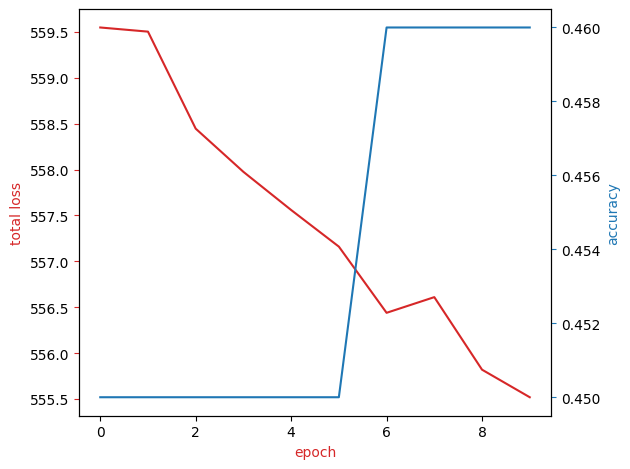

In [45]:
plot(cum_loss_list,acc_epoch)

In [46]:
evaluate(test_dataloader)

0.54

In [47]:
predict("انا احب هذا المنتج",text_pipeline )

'Positive'

In [48]:
predict("انا ما راح اشتري هذا المنتج",text_pipeline )

'Negative'

In [49]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

experiment = client.get_experiment_by_name(EXPERIMENT_NAME)
experiment_id = experiment.experiment_id

runs_df = mlflow.search_runs(
    experiment_ids=[experiment_id],
    order_by=["metrics.accuracy DESC"],
    max_results=1
)

In [50]:
if not runs_df.empty:
    best_run_id = runs_df.iloc[0]["run_id"]
    best_accuracy = runs_df.iloc[0]["metrics.accuracy"]
    
    print(f"Highest accuracy found: {best_accuracy} (Run ID: {best_run_id})")
    
    client.set_tag(
        run_id=best_run_id, 
        key="status", 
        value="production"
    )
    print("Successfully tagged the best run as 'production'.")
else:
    print("No runs found in this experiment.")

Highest accuracy found: 0.46 (Run ID: edcf520ff0864ab495322e1e0988b9fa)
Successfully tagged the best run as 'production'.


In [51]:
MODEL_URI = f"runs:/{best_run_id}/model"

model = mlflow.pytorch.load_model(MODEL_URI)

In [52]:
import torch

model.eval()

dummy_text = torch.tensor([1, 42, 33, 9, 15, 2, 88, 12, 5], dtype=torch.int64)
dummy_offsets = torch.tensor([0, 5], dtype=torch.int64)

onnx_file_path = "model.onnx"

torch.onnx.export(
    model,
    (dummy_text, dummy_offsets),
    onnx_file_path,
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["text", "offsets"],
    output_names=["output"],
    dynamic_axes={
        "text": {0: "total_tokens"},
        "offsets": {0: "batch_size"},
        "output": {0: "batch_size"},
    },
)

print(f"Model exported successfully to {onnx_file_path}")

Model exported successfully to model.onnx


In [53]:
import numpy as np
import onnxruntime as ort

session = ort.InferenceSession("model.onnx")

inputs = {
    "text": dummy_text.numpy(),
    "offsets": dummy_offsets.numpy(),
}
outputs = session.run(None, inputs)
print("ONNX Output Shape:", outputs[0].shape)

ONNX Output Shape: (2, 2)


2026-10-08 09:32:00.505009256 [W:onnxruntime:, graph_utils.cc:144 CanUpdateImplicitInputNameInSubgraphs]  Implicit input name /embedding/Slice_output_0 cannot be safely updated to /embedding/Concat_output_0 in one of the subgraphs.
2026-10-08 09:32:00.505531796 [W:onnxruntime:, graph_utils.cc:144 CanUpdateImplicitInputNameInSubgraphs]  Implicit input name /embedding/Slice_output_0 cannot be safely updated to /embedding/Concat_output_0 in one of the subgraphs.


In [54]:
import numpy as np
import onnxruntime as ort

session = ort.InferenceSession("model.onnx")

raw_texts = ["انا احب هذا المنتج", "انا ما راح اشتري هذا المنتج"]

text_list, offsets = [], [0]
for text in raw_texts:
    tokens = text_pipeline(text)
    if not tokens:
        tokens = [0]
    text_list.extend(tokens)
    offsets.append(len(tokens))

onnx_text = np.array(text_list, dtype=np.int64)
onnx_offsets = np.array(offsets[:-1], dtype=np.int64).cumsum()

inputs = {"text": onnx_text, "offsets": onnx_offsets}
logits = session.run(None, inputs)[0]

predicted_classes = np.argmax(logits, axis=1)
print("Predictions:", predicted_classes)

Predictions: [1 0]


2026-10-08 09:32:02.007783194 [W:onnxruntime:, graph_utils.cc:144 CanUpdateImplicitInputNameInSubgraphs]  Implicit input name /embedding/Slice_output_0 cannot be safely updated to /embedding/Concat_output_0 in one of the subgraphs.
2026-10-08 09:32:02.008245090 [W:onnxruntime:, graph_utils.cc:144 CanUpdateImplicitInputNameInSubgraphs]  Implicit input name /embedding/Slice_output_0 cannot be safely updated to /embedding/Concat_output_0 in one of the subgraphs.
